<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[11, 3, 8, 7, 5]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0286
3     0.0536
4     0.0852
5     0.1131
6     0.1413
7     0.1687
8     0.1419
9     0.1071
10    0.0799
11    0.0550
12    0.0256
Name: count, dtype: float64


<Axes: >

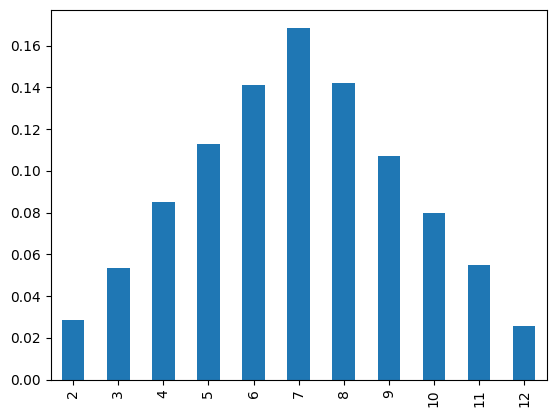

In [7]:
s.plot(kind='bar')

<Axes: >

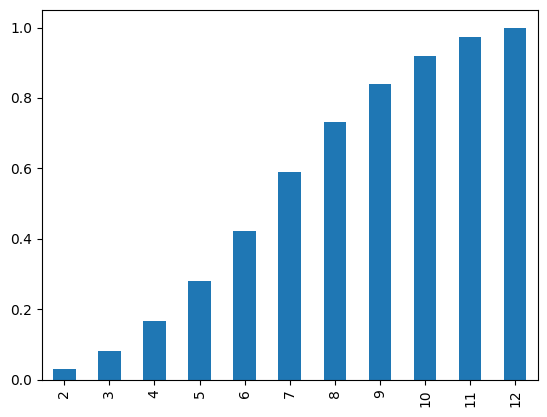

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[37.91821848 56.82390825 49.18008301 41.92328176 49.89085538 54.08815032
 47.41994067 46.29025973 52.09392954 50.84654022 46.57988724 47.95695077
 58.20660101 53.16417348 54.88304969 45.71504621 50.32271846 57.12992881
 56.41400788 56.0864679  44.04446634 55.28929469 52.43079523 47.01533203
 40.50330267 49.99607892 53.62872037 51.14367153 50.12959064 51.9224702
 52.43448475 54.73174842 42.84462017 51.53248885 51.02486978 44.25091196
 58.3045791  50.56157764 51.62773416 54.34078353 52.94196272 46.92043956
 45.00938719 56.72351098 51.89870229 51.15767615 51.41623429 50.5825665
 60.35751209 60.53227455 41.85647176 52.890754   47.00136089 51.78179256
 64.67485106 47.81347511 51.68515147 43.89024347 49.82570264 46.09107357
 52.43005501 41.91593595 49.86030404 52.62797925 52.83786399 40.25522896
 51.92976929 47.06427331 52.38151487 51.15106463 55.70850895 49.03943912
 44.49635532 49.12553995 54.52748561 46.59015883 54.51038771 45.82207883
 38.48970363 51.31721442 40.10999555 42.27293049 44.6

In [10]:
sample.mean()

np.float64(49.95623731700398)

(array([  5.,  38., 101., 210., 300., 227.,  89.,  21.,   8.,   1.]),
 array([34.0770565 , 37.63147537, 41.18589425, 44.74031312, 48.294732  ,
        51.84915087, 55.40356975, 58.95798862, 62.5124075 , 66.06682637,
        69.62124525]),
 <BarContainer object of 10 artists>)

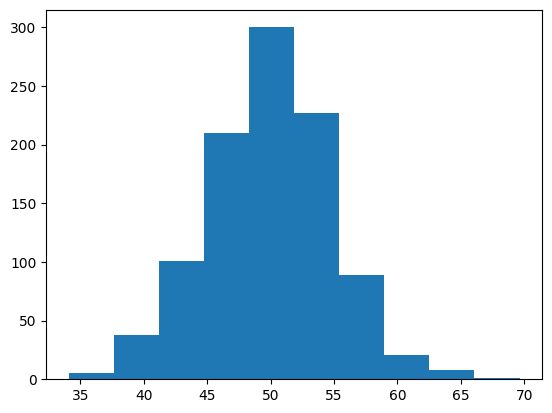

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(34.077056495877)

In [15]:
sample.max()

np.float64(69.62124524827648)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

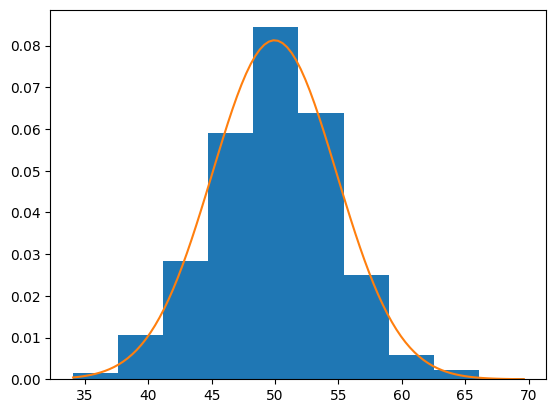

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_936/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

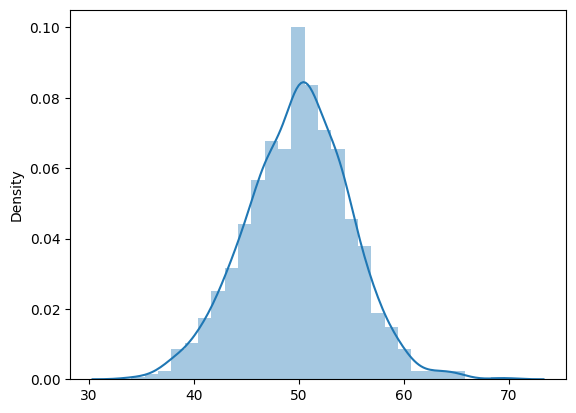

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([21.21576476, 19.08377682, 29.33734386, 26.25401286, 19.54216329,
       10.03972549, 19.38148215, 18.37075111, 31.79922519, 25.12428223,
       24.15413427, 19.72723416, 20.55067239, 28.30489058, 22.18575925,
       21.53262379, 25.54350422, 22.77791956, 26.26827272, 24.87146069,
       10.92885572, 23.16571244, 23.40944021, 23.25640892, 13.07151586,
       14.98737319, 12.92673157, 23.9805673 , 17.78416374, 17.09620437,
       26.30125084, 14.13186142, 22.95378464, 22.58022011, 15.68933233,
       25.89054983, 24.4024066 , 16.99984182, 20.47299366, 21.98475498,
       24.40433173, 20.40536467, 18.95631182, 21.33988529, 20.59422244,
       16.2472204 , 24.28820871, 22.69030219, 15.47889682, 21.83542853,
       38.00696951, 27.40043467, 15.98760336,  9.86674682, 17.042049  ,
        7.87929904, 20.66912972, 19.54840171, 20.53655694, 25.47322249,
       23.05552176, 19.598109  , 15.12765192, 17.96064904, 21.4258179 ,
       15.21175298, 15.85463017, 17.0812726 , 10.42168758, 19.66

(array([ 1.,  3.,  5.,  4.,  4., 12., 11., 12., 24., 17., 19., 20., 27.,
        21., 23., 25., 18., 12., 20.,  8.,  5., 14.,  9., 10., 16., 17.,
        34., 24., 44., 58., 46., 50., 56., 66., 44., 40., 39., 25., 35.,
        25., 16., 17., 11.,  6.,  1.,  1.,  1.,  1.,  1.,  2.]),
 array([ 7.87929904,  8.85501632,  9.8307336 , 10.80645088, 11.78216817,
        12.75788545, 13.73360273, 14.70932001, 15.6850373 , 16.66075458,
        17.63647186, 18.61218914, 19.58790642, 20.56362371, 21.53934099,
        22.51505827, 23.49077555, 24.46649284, 25.44221012, 26.4179274 ,
        27.39364468, 28.36936196, 29.34507925, 30.32079653, 31.29651381,
        32.27223109, 33.24794837, 34.22366566, 35.19938294, 36.17510022,
        37.1508175 , 38.12653479, 39.10225207, 40.07796935, 41.05368663,
        42.02940391, 43.0051212 , 43.98083848, 44.95655576, 45.93227304,
        46.90799032, 47.88370761, 48.85942489, 49.83514217, 50.81085945,
        51.78657674, 52.76229402, 53.7380113 , 54.71372858,

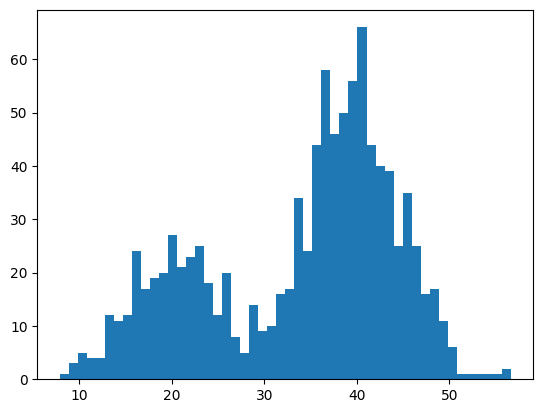

In [22]:
plt.hist(sample,bins=50)

In [25]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
model.fit(sample)

ValueError: Expected 2D array, got 1D array instead:
array=[21.21576476 19.08377682 29.33734386 26.25401286 19.54216329 10.03972549
 19.38148215 18.37075111 31.79922519 25.12428223 24.15413427 19.72723416
 20.55067239 28.30489058 22.18575925 21.53262379 25.54350422 22.77791956
 26.26827272 24.87146069 10.92885572 23.16571244 23.40944021 23.25640892
 13.07151586 14.98737319 12.92673157 23.9805673  17.78416374 17.09620437
 26.30125084 14.13186142 22.95378464 22.58022011 15.68933233 25.89054983
 24.4024066  16.99984182 20.47299366 21.98475498 24.40433173 20.40536467
 18.95631182 21.33988529 20.59422244 16.2472204  24.28820871 22.69030219
 15.47889682 21.83542853 38.00696951 27.40043467 15.98760336  9.86674682
 17.042049    7.87929904 20.66912972 19.54840171 20.53655694 25.47322249
 23.05552176 19.598109   15.12765192 17.96064904 21.4258179  15.21175298
 15.85463017 17.0812726  10.42168758 19.66083033 28.46724373 24.76261016
 21.09856368 19.09606203 15.28528742 17.44455389 18.41550012 17.4

How to use PDF in data science

In [29]:
dataset=sns.load_dataset("iris")

In [30]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
an

<Axes: xlabel='sepal_length', ylabel='Density'>

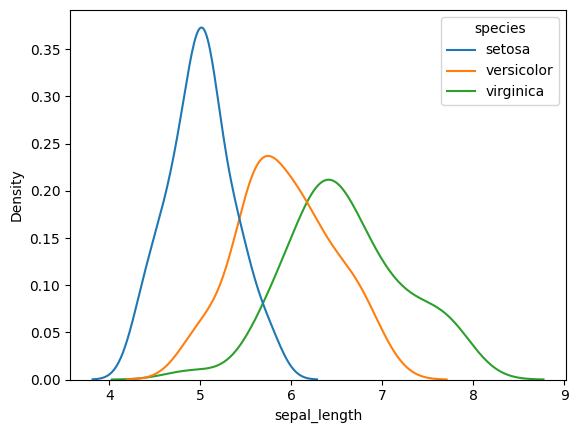

In [34]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

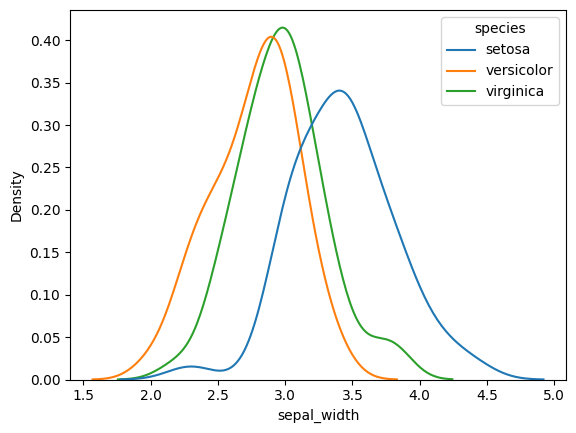

In [35]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

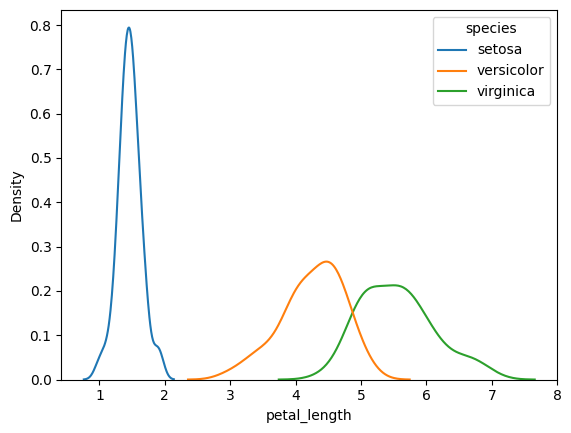

In [36]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

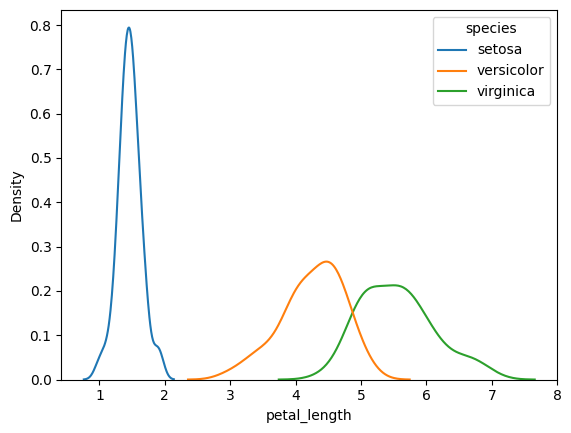

In [37]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [38]:
tips=sns.load_dataset("tips")

In [39]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

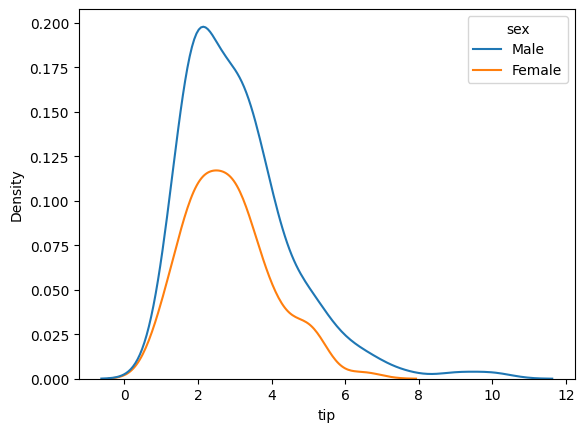

In [42]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

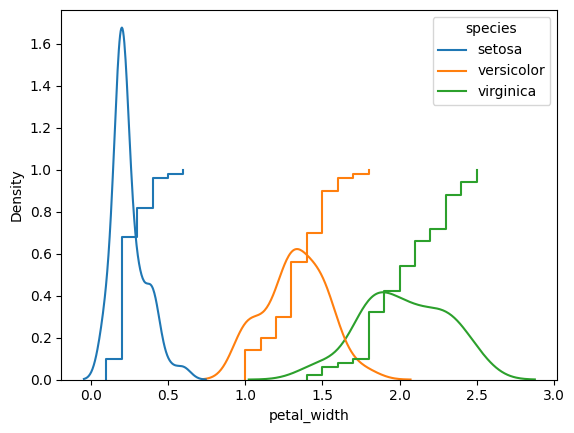

In [43]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [ ]:
#contour plots